# Lab 3-03：分塊策略——切在哪裡，決定找不找得到

**目標**：用同一份語料、同一個 embedding 模型、同一個 Chroma，只換切塊方式，量出檢索命中率的差別。

**你會學到**
- LlamaIndex 的兩種 splitter：`TokenTextSplitter`（固定長度）與 `MarkdownNodeParser`（依標題）
- 固定長度切塊會把表格、句子攔腰切斷
- contextual chunking：每塊前面補上「出自哪份文件、講什麼」，讓孤立的段落有主詞
- 用評估題庫（`data/qa.jsonl`）把「感覺比較好」變成數字

**前置**：Lab 3-02。原理見 `00_concepts.md` 第 3 節。

**對應投影片**：「固定長度切分的截斷」「依標題切分並保留章節」「語義切分 vs 代理切分」「補背景讓檢索失敗率下降」

![同一份文件，三種切線](images/chunk_cut_lines.jpg)

*圖：左邊固定長度，朱紅切線不管內容，常常切過表格中間；中間依標題，只在小節開頭下刀；右邊再替每一塊貼上文件標題的小標籤。*

## Step 1：讀文件與評估題庫

題庫每一題有問題、標準答案、以及「應該命中的文件 id」。`type` 標出這題靠關鍵字（錯誤碼、指令）還是靠語意（換句話說）。

In [1]:
from collections import Counter

from rag_utils import load_docs, load_qa

docs = load_docs()
qa = load_qa()
print(len(docs), "份文件，", len(qa), "題", Counter(q["type"] for q in qa))
print(qa[0])

30 份文件， 38 題 Counter({'keyword': 23, 'semantic': 15})
{'id': 'q01', 'question': 'TP-4021 是什麼錯誤？可以重試嗎？', 'answer': '冪等鍵衝突：同一個 Idempotency-Key 但請求內容不同，是呼叫端程式錯誤，不可重試。', 'doc_ids': ['svc-tidepay'], 'type': 'keyword'}


## Step 2：切法一——固定長度（`TokenTextSplitter`）

每 128 個 token 切一刀，相鄰兩塊重疊 16 個 token，避免剛好切在關鍵句上。簡單，但完全不看內容。
LlamaIndex 的切塊器輸入是 `Document`，輸出是 `Node`（一塊文字＋metadata＋來源文件 id）。

In [2]:
from llama_index.core import Document
from llama_index.core.node_parser import MarkdownNodeParser, TokenTextSplitter

li_docs = [Document(text=d.text, id_=d.doc_id) for d in docs]
token_splitter = TokenTextSplitter(chunk_size=128, chunk_overlap=16)

tidepay = next(x for x in li_docs if x.id_ == "svc-tidepay")
fixed_nodes = token_splitter.get_nodes_from_documents([tidepay])
print(len(fixed_nodes), "塊，來源：", fixed_nodes[0].ref_doc_id)
for node in fixed_nodes[4:6]:
    print("─" * 40)
    print(node.text)

8 塊，來源： svc-tidepay
────────────────────────────────────────
曾誤把保存時間改成 1 小時，造成重複扣款事故（INC-2026-0314），v3.4.1 已改回 24 小時。

## 錯誤碼

| 錯誤碼 | 意思 | 處理方式 |
|---|---|---|
| TP-4012 | 3D 驗證逾時 | 使用者超過 10
────────────────────────────────────────
驗證逾時 | 使用者超過 10 分鐘沒完成驗證，訂單保留，可重新付款 |
| TP-4021 | 冪等鍵衝突：同一鍵但請求內容不同 | 呼叫端程式錯誤，不可重試，要查呼叫端 |
| TP-4030 | 卡片被收單行拒絕 |


看錯誤碼表格：表頭（「錯誤碼｜意思｜處理方式」）和後面幾列被分到不同塊。拿到後一塊的人不知道每一欄是什麼意思。

## Step 3：切法二——依 Markdown 標題（`MarkdownNodeParser`）

技術文件本來就有結構，`## 小節` 就是作者畫好的分界線。照著切，一塊就是一個完整的主題，表格不會被切開。

In [3]:
md_parser = MarkdownNodeParser()
md_nodes = md_parser.get_nodes_from_documents([tidepay])
for node in md_nodes:
    print(f"{len(node.text):4d} 字  {node.text.splitlines()[0]:<20} metadata={node.metadata}")

  75 字  # tide-pay 支付閘道服務說明  metadata={'header_path': '/'}
 100 字  ## 這個服務做什麼           metadata={'header_path': '/tide-pay 支付閘道服務說明/'}
 245 字  ## 付款流程              metadata={'header_path': '/tide-pay 支付閘道服務說明/'}
 123 字  ## 冪等鍵               metadata={'header_path': '/tide-pay 支付閘道服務說明/'}
 284 字  ## 錯誤碼               metadata={'header_path': '/tide-pay 支付閘道服務說明/'}
  73 字  ## 設定                metadata={'header_path': '/tide-pay 支付閘道服務說明/'}


## Step 4：問題來了——孤立的小節沒有主詞

看下面兩塊：第一塊只說「2026 年 9 月壓測事故」，第二塊是「版本紀錄」，都沒說是哪個服務。問「消費落後怎麼辦」或「anchor-order v7 改了什麼」時，向量很難把它們跟問題連起來。

In [4]:
def last_section(doc_id: str) -> str:
    doc = next(x for x in li_docs if x.id_ == doc_id)
    return md_parser.get_nodes_from_documents([doc])[-1].text


print(last_section("rb-mq-consumer-lag"))
print("═" * 40)
print(last_section("svc-anchor-order"))

## 參考

2026 年 9 月壓測事故 INC-2026-0921。
════════════════════════════════════════
## 版本紀錄

- v7.0.0（2026-09）：狀態機改寫，取消規則改成「PICKING 前可自行取消」，之前是「PAID 前才可取消」。
- v6.8.2：修正跨月訂單編號重複。
- 服務埠：8081。


## Step 5：切法三——contextual chunking

Anthropic 在 2024 年提出的做法：每一塊前面補一段「這塊在整份文件裡的位置」。最便宜的版本是補文件標題；
進一步請 LLM 為每份文件寫一句摘要，一起補上。LlamaIndex 沒有現成元件做這件事，但它只是字串相接，兩行就好。

In [5]:
titles = {d.doc_id: d.title for d in docs}
node = md_parser.get_nodes_from_documents([next(x for x in li_docs if x.id_ == "rb-mq-consumer-lag")])[-1]
print(f"《{titles[node.ref_doc_id]}》\n{node.text}")

《Runbook：current-mq 消費落後（consumer lag）》
## 參考

2026 年 9 月壓測事故 INC-2026-0921。


## Step 6：請 LLM 為每份文件寫一句摘要

每份文件只呼叫一次（不是每塊一次），30 份文件約一兩分鐘。摘要只在建索引時做，不影響查詢速度。
Ollama 同時被很多人用時偶爾逾時，所以用 `rag_utils.ask`（`chat` 加上重試）。

In [6]:
from rag_utils import ask as chat_retry  # chat 加上較長逾時與重試

summaries = {
    d.doc_id: chat_retry([{
        "role": "user",
        "content": f"用一句繁體中文（40 字以內）說明這份文件在講什麼問題，不要列出版本、團隊、日期，只回那一句：\n\n{d.text[:1500]}",
    }]).strip().lstrip("# ").replace("\n", " ")
    for d in docs
}
for doc_id in ["rb-mq-consumer-lag", "svc-anchor-order", "archive-svc-anchor-order-v6"]:
    print(f"{doc_id:<30} {summaries[doc_id]}")

rb-mq-consumer-lag             當 current-mq 某個 consumer group 消費落後超過 50,000 笔時，需排查並調整消費者數量，處理卡在壞訊息的消費者，或升級嚴重度以避免資料損失。
svc-anchor-order               anchor-order 管理訂單全生命周期，包括建立、付款、揀貨、出貨、完成与取消，支持会员在特定状态下自行取消或通过退貨流程。
archive-svc-anchor-order-v6    本文件說明 anchor-order v6 舊版的訂單服務狀態、錯誤碼及版本更新紀錄。


## Step 7：四種切法，全部切一遍

統一轉成 `Chunk`（id、來源文件、文字），方便丟進 Chroma。依標題切時，第 0 塊是文件標題和 metadata 那一行，跳過。

In [7]:
from rag_utils import Chunk


def to_chunks(nodes, prefix=lambda doc_id: "") -> list[Chunk]:
    out, count = [], Counter()
    for n in nodes:
        doc_id = n.ref_doc_id
        out.append(Chunk(f"{doc_id}#{count[doc_id]}", doc_id, prefix(doc_id) + n.text))
        count[doc_id] += 1
    return out


md_all = [n for d in li_docs for n in md_parser.get_nodes_from_documents([d])[1:]]
chunk_sets = {
    "固定 128 token": to_chunks(token_splitter.get_nodes_from_documents(li_docs)),
    "依標題": to_chunks(md_all),
    "依標題＋標題": to_chunks(md_all, lambda d: f"《{titles[d]}》\n"),
    "依標題＋標題＋摘要": to_chunks(md_all, lambda d: f"《{titles[d]}》{summaries[d]}\n"),
}
for name, cs in chunk_sets.items():
    lengths = [len(c.text) for c in cs]
    print(f"{name:<14} {len(cs):4d} 塊，平均 {sum(lengths) / len(lengths):5.0f} 字，最長 {max(lengths)} 字")

固定 128 token    153 塊，平均   123 字，最長 250 字
依標題             113 塊，平均   125 字，最長 473 字
依標題＋標題          113 塊，平均   148 字，最長 488 字
依標題＋標題＋摘要       113 塊，平均   206 字，最長 557 字


## Step 8：看長度分布

固定長度擠在同一個區間；依標題切則長短不一，有些小節只有一兩行，有些是整張表格。

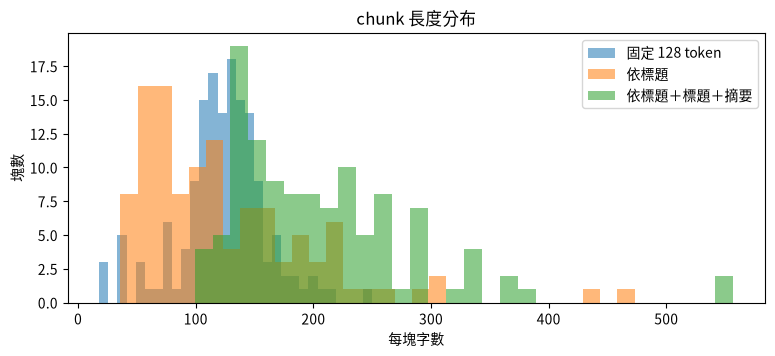

In [8]:
import matplotlib.pyplot as plt

from course_utils.viz import setup_cjk

setup_cjk()

plt.figure(figsize=(9, 3.5))
for name in ["固定 128 token", "依標題", "依標題＋標題＋摘要"]:
    plt.hist([len(c.text) for c in chunk_sets[name]], bins=30, alpha=0.55, label=name)
plt.xlabel("每塊字數")
plt.ylabel("塊數")
plt.legend()
plt.title("chunk 長度分布")
plt.show()

## Step 9：每種切法建一個 Chroma collection

`build_collection` 就是 Lab 3-02 Step 4、5 那幾行（建 collection、分批 `add`）。四組約 450 塊，需要一點時間。

In [9]:
from rag_utils import build_collection

collections = {name: build_collection(cs, f"chunk_{i}") for i, (name, cs) in enumerate(chunk_sets.items())}
print({name: col.count() for name, col in collections.items()})

{'固定 128 token': 153, '依標題': 113, '依標題＋標題': 113, '依標題＋標題＋摘要': 113}


## Step 10：怎麼算「命中」

每題檢索前 10 塊，轉成文件排名（同一份文件只算第一次出現），看標準文件有沒有在前 k 名。
- **Hit@k**：前 k 名有沒有命中，有就 1、沒有就 0，全部題目取平均。
- **MRR**：第一個命中的名次取倒數（第 1 名＝1、第 2 名＝0.5…）再平均，越接近 1 越好。

這兩個指標各只有三行，所以不另外裝評估套件（Lab 3-06 會細講）。

In [10]:
import numpy as np

from rag_utils import dedup_docs, hit_at_k, reciprocal_rank, vector_search


def evaluate(col) -> dict:
    hit1, hit3, rr = [], [], []
    for q in qa:
        ranked = dedup_docs(vector_search(col, q["question"], k=10))
        hit1.append(hit_at_k(ranked, q["doc_ids"], 1))
        hit3.append(hit_at_k(ranked, q["doc_ids"], 3))
        rr.append(reciprocal_rank(ranked, q["doc_ids"]))
    return {"Hit@1": np.mean(hit1), "Hit@3": np.mean(hit3), "MRR": np.mean(rr)}


results = {name: evaluate(col) for name, col in collections.items()}
for name, r in results.items():
    print(f"{name:<14} " + "  ".join(f"{k} {v:.2f}" for k, v in r.items()))

固定 128 token   Hit@1 0.89  Hit@3 1.00  MRR 0.94
依標題            Hit@1 0.89  Hit@3 1.00  MRR 0.95
依標題＋標題         Hit@1 0.82  Hit@3 1.00  MRR 0.91
依標題＋標題＋摘要      Hit@1 0.82  Hit@3 0.95  MRR 0.89


## Step 11：畫成長條圖

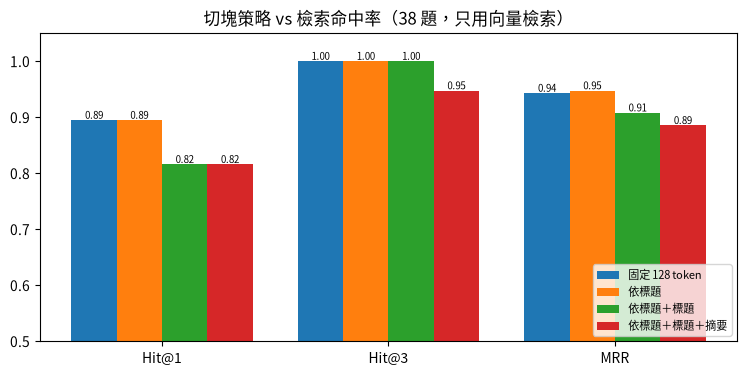

In [11]:
metrics = ["Hit@1", "Hit@3", "MRR"]
x = np.arange(len(metrics))
width = 0.2
plt.figure(figsize=(9, 4))
for n, name in enumerate(results):
    bars = plt.bar(x + (n - 1.5) * width, [results[name][m] for m in metrics], width, label=name)
    plt.bar_label(bars, fmt="%.2f", fontsize=7)
plt.xticks(x, metrics)
plt.ylim(0.5, 1.05)
plt.legend(fontsize=8, loc="lower right")
plt.title(f"切塊策略 vs 檢索命中率（{len(qa)} 題，只用向量檢索）")
plt.show()

## Step 12：哪幾題因為切法不同而翻盤？

平均數會藏住細節。列出「固定長度」和「依標題＋標題＋摘要」第一名不同對錯的題目。

In [12]:
a, b = "固定 128 token", "依標題＋標題＋摘要"
for q in qa:
    da = vector_search(collections[a], q["question"], k=1)[0].split("#")[0]
    db = vector_search(collections[b], q["question"], k=1)[0].split("#")[0]
    ok_a, ok_b = da in q["doc_ids"], db in q["doc_ids"]
    if ok_a != ok_b:
        print(f"{q['id']} {q['question'][:22]:<24} 固定：{'對' if ok_a else '錯'}（{da}）  補上下文：{'對' if ok_b else '錯'}（{db}）")

q01 TP-4021 是什麼錯誤？可以重試嗎？     固定：對（svc-tidepay）  補上下文：錯（rb-tp-4012-3ds-timeout）
q02 TP-4012 每小時多少筆以上才需要處理？   固定：錯（rb-tp-5003-acquirer-failover）  補上下文：對（rb-tp-4012-3ds-timeout）
q11 hf.notify.request.v2 有   固定：對（svc-current-mq）  補上下文：錯（pm-2026-0921-mq-lag）
q12 breakwater 的 jwks_cach   固定：對（svc-breakwater）  補上下文：錯（archive-svc-breakwater-v2）
q21 新版上線後發現有問題，要怎麼退回舊版？需要誰   固定：對（faq-deploy）  補上下文：錯（archive-svc-anchor-order-v6）
q24 我需要登入正式環境的資料庫修資料，流程是什麼   固定：錯（faq-deploy）  補上下文：對（faq-prod-access）
q30 資料倉儲裡的手機號碼會怎麼顯示？         固定：錯（policy-data-retention）  補上下文：對（svc-sandbar-dw）
q35 acquirer_timeout_ms 設多   固定：對（svc-tidepay）  補上下文：錯（pm-2026-0607-auth-outage）
q38 hfctl gw breaker reset   固定：對（rb-bw-503-circuit）  補上下文：錯（faq-deploy）


## Step 13：結果跟預期不一樣

在這份語料上，**補標題沒有讓向量檢索變好，Hit@1 反而掉了**。看翻盤的題目就知道原因：
- breakwater 新版和 v2.5 舊版的標題幾乎一樣，補上標題後兩份文件的每一塊都更像，舊文件反而搶到第一名。
- `rb-tp-4012` 的標題裡有「TP-4012」，問 TP-4021 時這個幾乎一樣的代碼把它拉上來。

標題讓同一個服務的文件互相靠近，區分度下降。網路上「contextual chunking 降低 49% 檢索失敗」是在別人的語料上量的；
**換到你的資料，一定要自己量**。這正是準備題庫的理由。

## Step 14：但對關鍵字檢索，補標題很有用

小節裡常常沒寫服務名稱（「版本紀錄」那塊沒寫 anchor-order）。關鍵字檢索只看字面，沒有這個字就找不到。
用 `rank_bm25`（下一本會細講）比較同樣兩種切法，只看關鍵字題：

In [13]:
from rag_utils import BM25Index

kw_questions = [q for q in qa if q["type"] == "keyword"]
for name in ["依標題", "依標題＋標題"]:
    bm25 = BM25Index(chunk_sets[name])
    hit1 = np.mean([hit_at_k(dedup_docs(bm25.search(q["question"], 10)), q["doc_ids"], 1) for q in kw_questions])
    print(f"BM25  {name:<10} 關鍵字題 Hit@1 = {hit1:.2f}")

BM25  依標題        關鍵字題 Hit@1 = 0.74
BM25  依標題＋標題     關鍵字題 Hit@1 = 0.83


補上標題之後，每一塊都帶著服務名稱，問題裡提到服務名時 BM25 就比對得到。
所以後面的 notebook 仍然用「依標題＋標題」（`rag_utils.chunk_docs`）：向量檢索的副作用用 metadata 過濾擋掉舊文件，關鍵字檢索拿到主詞。

投影片上還有兩種切法這裡沒做：**語義切分**（相鄰句子的向量差太多就切一刀，LlamaIndex 有 `SemanticSplitterNodeParser`）和**代理切分**（請 LLM 判斷每段是不是獨立的知識）。
對已經有清楚標題的技術文件，依標題切通常就夠了；這兩種留給沒有結構的長文（會議逐字稿、客服對話）。

## 試試看

1. 把 `TokenTextSplitter` 改成 `chunk_size=256, chunk_overlap=32`，重跑 Step 7～11。塊變大，命中率怎麼變？塞進 prompt 的字數又怎麼變？
2. 在前綴裡除了標題，再補上 metadata 的「服務」和「版本」（`doc.meta`），看 Hit@1 有沒有變化。
3. 試 `SemanticSplitterNodeParser`（要給它一個 LlamaIndex 的 embedding 物件：`OllamaEmbedding(model_name="bge-m3")`），跟依標題切比一比。

## 小結

- 固定長度最簡單，但會切斷表格與句子；有結構的文件就用 `MarkdownNodeParser` 照標題切。
- 補上下文不是穩賺：在這份語料上它讓向量檢索更分不清新舊版，卻讓關鍵字檢索拿到主詞。每個「最佳實踐」都要用自己的題庫量過。
- 錯誤碼這類字面細節，換切法也救不回來。下一本 Lab 3-04 把 BM25 關鍵字檢索和向量檢索合起來。